#Setup

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import random
import numpy as np
import matplotlib.pyplot as plt

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("PyTorch:", torch.__version__)

Device: cuda
PyTorch: 2.11.0+cu130


#Configuration

In [2]:
NUM_SYMBOLS = 8
NUM_VALUES = 8

NUM_CONTEXT_PAIRS = 3
SEQ_PAIRS = NUM_CONTEXT_PAIRS + 1

D_MODEL = 64
N_HEADS = 4
N_LAYERS = 2
D_FF = 128

BATCH_SIZE = 256

NUM_TRAIN_STEPS = 5000
LEARNING_RATE = 1e-3

SYMBOL_OFFSET = 0
VALUE_OFFSET = NUM_SYMBOLS

MASK_TOKEN = NUM_SYMBOLS + NUM_VALUES
VOCAB_SIZE = MASK_TOKEN + 1

#ICL Task / Data Generation

In [3]:
def generate_icl_batch(batch_size):
    mappings = torch.randint(
        0,
        NUM_VALUES,
        (batch_size, NUM_SYMBOLS)
    )

    context_symbols = torch.randint(
        0,
        NUM_SYMBOLS,
        (batch_size, NUM_CONTEXT_PAIRS)
    )

    context_values = torch.gather(
        mappings,
        1,
        context_symbols
    )

    query_position = torch.randint(
        0,
        NUM_CONTEXT_PAIRS,
        (batch_size,)
    )

    query_symbols = context_symbols[
        torch.arange(batch_size),
        query_position
    ]

    query_values = mappings[
        torch.arange(batch_size),
        query_symbols
    ]

    symbols = torch.cat(
        [context_symbols, query_symbols.unsqueeze(1)],
        dim=1
    )

    values = torch.cat(
        [
            context_values,
            query_values.unsqueeze(1)
        ],
        dim=1
    )

    tokens = torch.empty(
        batch_size,
        SEQ_PAIRS * 2,
        dtype=torch.long
    )

    tokens[:, 0::2] = symbols
    tokens[:, 1::2] = values + VALUE_OFFSET

    inputs = tokens.clone()
    inputs[:, -1] = MASK_TOKEN

    return (
        inputs.to(device),
        query_values.to(device),
        symbols.to(device),
        values.to(device)
    )

# Base Transformer

In [4]:
class InductionTransformer(nn.Module):

    def __init__(
        self,
        vocab_size,
        max_seq_len,
        d_model=64,
        n_heads=4,
        n_layers=2,
        d_ff=128
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            d_model
        )

        self.position_embedding = nn.Embedding(
            max_seq_len,
            d_model
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=d_ff,
            dropout=0.1,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=n_layers
        )

        self.output = nn.Linear(
            d_model,
            vocab_size
        )

    def forward(self, tokens):

        batch_size, seq_len = tokens.shape

        positions = torch.arange(
            seq_len,
            device=tokens.device
        )

        positions = positions.unsqueeze(0).expand(
            batch_size,
            seq_len
        )

        x = (
            self.embedding(tokens)
            +
            self.position_embedding(positions)
        )

        x = self.transformer(x)

        logits = self.output(x)

        return logits

In [5]:
model = InductionTransformer(
    vocab_size=VOCAB_SIZE,
    max_seq_len=2 * SEQ_PAIRS,
    d_model=D_MODEL,
    n_heads=N_HEADS,
    n_layers=N_LAYERS,
    d_ff=D_FF
).to(device)

# Training and Evaluation Functions

In [6]:
def train_model(
    model,
    steps=5000,
    batch_size=256,
    learning_rate=1e-3,
    print_every=500
):

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.AdamW(
        model.parameters(),
        lr=learning_rate
    )

    model.train()

    losses = []
    accuracies = []

    for step in range(1, steps + 1):

        inputs, targets, _, _ = generate_icl_batch(
            batch_size
        )

        optimizer.zero_grad()

        logits = model(inputs)

        # Only prediction at final MASK position matters
        final_logits = logits[:, -1, :]

        # Target values occupy tokens 20-39
        target_tokens = targets + VALUE_OFFSET

        loss = criterion(
            final_logits,
            target_tokens
        )

        loss.backward()

        optimizer.step()

        predictions = final_logits.argmax(dim=1)

        accuracy = (
            predictions == target_tokens
        ).float().mean()

        losses.append(loss.item())
        accuracies.append(accuracy.item())

        if step % print_every == 0:

            print(
                f"Step {step:5d} | "
                f"Loss {loss.item():.4f} | "
                f"Accuracy {accuracy.item() * 100:.1f}%"
            )

    return losses, accuracies

# Generation 0 Training

In [7]:
losses, accuracies = train_model(
    model,
    steps=NUM_TRAIN_STEPS,
    batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE
)

Step   500 | Loss 0.8634 | Accuracy 50.0%
Step  1000 | Loss 0.1924 | Accuracy 93.4%
Step  1500 | Loss 0.0784 | Accuracy 98.0%
Step  2000 | Loss 0.0593 | Accuracy 98.8%
Step  2500 | Loss 0.0186 | Accuracy 99.2%
Step  3000 | Loss 0.0653 | Accuracy 98.8%
Step  3500 | Loss 0.0115 | Accuracy 99.6%
Step  4000 | Loss 0.0342 | Accuracy 99.6%
Step  4500 | Loss 0.0009 | Accuracy 100.0%
Step  5000 | Loss 0.0470 | Accuracy 99.2%


In [8]:
@torch.no_grad()
def evaluate_model(
    model,
    num_examples=5000,
    batch_size=256
):

    model.eval()

    criterion = nn.CrossEntropyLoss(reduction="sum")

    total_loss = 0.0
    correct = 0
    total = 0

    remaining = num_examples

    while remaining > 0:

        current_batch = min(
            batch_size,
            remaining
        )

        inputs, targets, _, _ = generate_icl_batch(
            current_batch
        )

        logits = model(inputs)

        final_logits = logits[:, -1, :]

        target_tokens = targets + VALUE_OFFSET

        total_loss += criterion(
            final_logits,
            target_tokens
        ).item()

        predictions = final_logits.argmax(dim=1)

        correct += (
            predictions == target_tokens
        ).sum().item()

        total += current_batch

        remaining -= current_batch

    accuracy = correct / total
    loss = total_loss / total
    perplexity = np.exp(loss)

    return accuracy, loss, perplexity

In [9]:
generation_0_accuracy, generation_0_loss, generation_0_perplexity = (
    evaluate_model(model)
)

print(
    f"Generation 0 | "
    f"Accuracy: {generation_0_accuracy * 100:.2f}% | "
    f"Loss: {generation_0_loss:.4f} | "
    f"Perplexity: {generation_0_perplexity:.4f}"
)

Generation 0 | Accuracy: 100.00% | Loss: 0.0001 | Perplexity: 1.0001


# Base Model Collapse Experiment

In [10]:
@torch.no_grad()
def generate_synthetic_dataset(model, dataset_size=1000, batch_size=256):
    model.eval()

    all_inputs = []
    all_targets = []

    for start in range(0, dataset_size, batch_size):
        current_batch = min(batch_size, dataset_size - start)

        inputs, true_targets, _, _ = generate_icl_batch(current_batch)

        inputs = inputs.to(device)

        logits = model(inputs)
        predictions = logits[:, -1, :].argmax(dim=-1)

        # Convert predicted value-token IDs back to value IDs
        predicted_values = predictions - VALUE_OFFSET

        # Keep only valid value predictions
        predicted_values = predicted_values.clamp(0, NUM_VALUES - 1)

        all_inputs.append(inputs.cpu())
        all_targets.append(predicted_values.cpu())

    return (
        torch.cat(all_inputs, dim=0),
        torch.cat(all_targets, dim=0)
    )

In [11]:
def train_on_dataset(model, inputs, targets, steps=500):
    model.train()

    inputs = inputs.to(device)
    targets = targets.to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.CrossEntropyLoss()

    dataset_size = inputs.size(0)

    for step in range(steps):
        indices = torch.randint(
            0,
            dataset_size,
            (min(BATCH_SIZE, dataset_size),),
            device=device
        )

        batch_inputs = inputs[indices]
        batch_targets = targets[indices]

        optimizer.zero_grad()

        logits = model(batch_inputs)
        final_logits = logits[:, -1, :]

        loss = criterion(
            final_logits,
            batch_targets + VALUE_OFFSET
        )

        loss.backward()
        optimizer.step()

    return model

In [12]:
NUM_GENERATIONS = 5
COLLAPSE_DATASET_SIZE = 1000
COLLAPSE_TRAIN_STEPS = 500

generation_models = [model]

generation_metrics = {
    "base": {
        "accuracy": [generation_0_accuracy],
        "loss": [generation_0_loss],
        "perplexity": [generation_0_perplexity]
    },
    "extended": {
        "accuracy": [],
        "loss": [],
        "perplexity": []
    }
}

current_model = model

for generation in range(1, NUM_GENERATIONS + 1):
    print(f"\nGenerating Generation {generation} dataset...")

    generated_inputs, generated_targets = generate_synthetic_dataset(
        current_model,
        dataset_size=COLLAPSE_DATASET_SIZE
    )

    print("Training Generation", generation)

    next_model = InductionTransformer(
    vocab_size=VOCAB_SIZE,
    max_seq_len=2 * SEQ_PAIRS,
    d_model=D_MODEL,
    n_heads=N_HEADS,
    n_layers=N_LAYERS,
    d_ff=D_FF
).to(device)

    next_model = train_on_dataset(
        next_model,
        generated_inputs,
        generated_targets,
        steps=COLLAPSE_TRAIN_STEPS
    )

    accuracy, loss, perplexity = evaluate_model(next_model)

    print(
    f"Base G{generation} | "
    f"Accuracy: {accuracy * 100:.2f}% | "
    f"Loss: {loss:.4f} | "
    f"Perplexity: {perplexity:.4f}"
  )

    generation_models.append(next_model)

    generation_metrics["base"]["accuracy"].append(accuracy)
    generation_metrics["base"]["loss"].append(loss)
    generation_metrics["base"]["perplexity"].append(perplexity)

    current_model = next_model


Generating Generation 1 dataset...
Training Generation 1
Base G1 | Accuracy: 63.08% | Loss: 1.5502 | Perplexity: 4.7126

Generating Generation 2 dataset...
Training Generation 2
Base G2 | Accuracy: 52.88% | Loss: 2.3148 | Perplexity: 10.1232

Generating Generation 3 dataset...
Training Generation 3
Base G3 | Accuracy: 51.96% | Loss: 2.8030 | Perplexity: 16.4937

Generating Generation 4 dataset...
Training Generation 4
Base G4 | Accuracy: 50.68% | Loss: 3.0029 | Perplexity: 20.1436

Generating Generation 5 dataset...
Training Generation 5
Base G5 | Accuracy: 49.20% | Loss: 3.3227 | Perplexity: 27.7350


# Extended Tranformer

In [13]:
class ExtendedTransformer(nn.Module):

    def __init__(
        self,
        vocab_size,
        max_seq_len,
        d_model=64,
        n_heads=4,
        n_layers=2,
        d_ff=128
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            d_model
        )

        self.position_embedding = nn.Embedding(
            max_seq_len,
            d_model
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=d_ff,
            dropout=0.1,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=n_layers
        )

        self.output = nn.Linear(
            d_model,
            vocab_size
        )

    def forward(self, tokens):

        batch_size, seq_len = tokens.shape

        positions = torch.arange(
            seq_len,
            device=tokens.device
        )

        positions = positions.unsqueeze(0).expand(
            batch_size,
            seq_len
        )

        x = (
            self.embedding(tokens)
            + self.position_embedding(positions)
        )

        # Causal mask
        causal_mask = torch.triu(
            torch.ones(
                seq_len,
                seq_len,
                device=tokens.device,
                dtype=torch.bool
            ),
            diagonal=1
        )

        x = self.transformer(
            x,
            mask=causal_mask
        )

        return self.output(x)

# Extended Model Training

In [14]:
extended_model = ExtendedTransformer(
    vocab_size=VOCAB_SIZE,
    max_seq_len=2 * SEQ_PAIRS,
    d_model=D_MODEL,
    n_heads=N_HEADS,
    n_layers=N_LAYERS,
    d_ff=D_FF
).to(device)

In [15]:
def train_extended_model(
    model,
    steps=1000,
    batch_size=256
):

    model.train()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=1e-3
    )

    criterion = nn.CrossEntropyLoss()

    for step in range(steps):

        _, _, symbols, values = generate_icl_batch(
            batch_size
        )

        tokens = torch.empty(
            batch_size,
            2 * SEQ_PAIRS,
            dtype=torch.long
        )

        tokens[:, 0::2] = symbols
        tokens[:, 1::2] = values + VALUE_OFFSET

        tokens = tokens.to(device)

        # Predict next token
        input_tokens = tokens[:, :-1]
        target_tokens = tokens[:, 1:]

        optimizer.zero_grad()

        logits = model(input_tokens)

        loss = criterion(
            logits.reshape(-1, VOCAB_SIZE),
            target_tokens.reshape(-1)
        )

        loss.backward()
        optimizer.step()

        if (step + 1) % 200 == 0:
            print(
                f"Step {step + 1}/{steps} "
                f"Loss: {loss.item():.4f}"
            )

    return model

In [16]:
extended_model = train_extended_model(
    extended_model,
    steps=1000,
    batch_size=256
)

Step 200/1000 Loss: 1.6904
Step 400/1000 Loss: 1.5893
Step 600/1000 Loss: 1.5455
Step 800/1000 Loss: 1.5486
Step 1000/1000 Loss: 1.5343


In [17]:
extended_g0_accuracy, extended_g0_loss, extended_g0_perplexity = (
    evaluate_model(extended_model)
)

In [18]:
generation_metrics["extended"]["accuracy"].append(
    extended_g0_accuracy
)

generation_metrics["extended"]["loss"].append(
    extended_g0_loss
)

generation_metrics["extended"]["perplexity"].append(
    extended_g0_perplexity
)

In [ ]:
print(
    f"Extended G0 | "
    f"Accuracy: {extended_g0_accuracy * 100:.2f}% | "
    f"Loss: {extended_g0_loss:.4f} | "
    f"Perplexity: {extended_g0_perplexity:.4f}"
)

Extended G0 | Accuracy: 16.36% | Loss: 4.6556 | Perplexity: 105.1735


Extended G0 | Accuracy: 50.32% | Loss: 1.8628 | Perplexity: 6.4420


In [ ]:
@torch.no_grad()
def generate_extended_dataset(
    model,
    dataset_size=1000,
    batch_size=256
):
    model.eval()

    generated_inputs = []
    generated_targets = []

    for start in range(0, dataset_size, batch_size):

        current_batch = min(
            batch_size,
            dataset_size - start
        )

        # Start with a random symbol
        sequences = torch.randint(
            0,
            NUM_SYMBOLS,
            (current_batch, 1),
            device=device
        )

        for position in range(1, 2 * SEQ_PAIRS):

            logits = model(sequences)[:, -1, :]

            # Restrict what the model is allowed to generate.
            if position % 2 == 1:
                # VALUE position
                allowed = logits[
                    :,
                    VALUE_OFFSET:VALUE_OFFSET + NUM_VALUES
                ]

                next_token = (
                    allowed.argmax(dim=-1)
                    + VALUE_OFFSET
                )

            else:
                # SYMBOL position
                allowed = logits[
                    :,
                    :NUM_SYMBOLS
                ]

                next_token = allowed.argmax(
                    dim=-1
                )

            next_token = next_token.unsqueeze(1)

            sequences = torch.cat(
                [sequences, next_token],
                dim=1
            )

        # Final generated value becomes target
        targets = (
            sequences[:, -1] - VALUE_OFFSET
        )

        # Input contains everything except final answer
        inputs = sequences.clone()
        inputs[:, -1] = MASK_TOKEN

        generated_inputs.append(
            inputs.cpu()
        )

        generated_targets.append(
            targets.cpu()
        )

    return (
        torch.cat(generated_inputs),
        torch.cat(generated_targets)
    )

# Extended Model Collapse Experiment

In [ ]:
NUM_EXTENDED_GENERATIONS = 5
EXTENDED_DATASET_SIZE = 1000
EXTENDED_TRAIN_STEPS = 500

extended_generation_models = [
    extended_model
]

extended_generation_accuracies = []

current_model = extended_model

for generation in range(1, NUM_EXTENDED_GENERATIONS + 1):

    print(
        f"\nGenerating Extended Generation {generation} dataset..."
    )

    generated_inputs, generated_targets = (
        generate_extended_dataset(
            current_model,
            dataset_size=EXTENDED_DATASET_SIZE
        )
    )

    print(
        f"Training Extended Generation {generation}"
    )

    next_model = InductionTransformer(
        vocab_size=VOCAB_SIZE,
        max_seq_len=2 * SEQ_PAIRS,
        d_model=D_MODEL,
        n_heads=N_HEADS,
        n_layers=N_LAYERS,
        d_ff=D_FF
    ).to(device)

    next_model = train_on_dataset(
        next_model,
        generated_inputs,
        generated_targets,
        steps=EXTENDED_TRAIN_STEPS
    )

    accuracy, loss, perplexity = evaluate_model(next_model)

    print(
      f"Extended G{generation} | "
      f"Accuracy: {accuracy * 100:.2f}% | "
      f"Loss: {loss:.4f} | "
      f"Perplexity: {perplexity:.4f}"
    )

    extended_generation_models.append(
        next_model
    )

    generation_metrics["extended"]["accuracy"].append(
      accuracy
    )

    generation_metrics["extended"]["loss"].append(
      loss
    )

    generation_metrics["extended"]["perplexity"].append(
      perplexity
    )

    current_model = next_model


Generating Extended Generation 1 dataset...
Training Extended Generation 1
Extended G1 | Accuracy: 12.66% | Loss: 9.3976 | Perplexity: 12059.3242

Generating Extended Generation 2 dataset...
Training Extended Generation 2
Extended G2 | Accuracy: 12.48% | Loss: 8.9458 | Perplexity: 7675.8083

Generating Extended Generation 3 dataset...
Training Extended Generation 3
Extended G3 | Accuracy: 13.14% | Loss: 9.0129 | Perplexity: 8208.0059

Generating Extended Generation 4 dataset...
Training Extended Generation 4
Extended G4 | Accuracy: 12.98% | Loss: 9.1289 | Perplexity: 9217.8623

Generating Extended Generation 5 dataset...
Training Extended Generation 5
Extended G5 | Accuracy: 12.78% | Loss: 8.9403 | Perplexity: 7633.6040


In [ ]:
generations = list(range(NUM_GENERATIONS + 1))

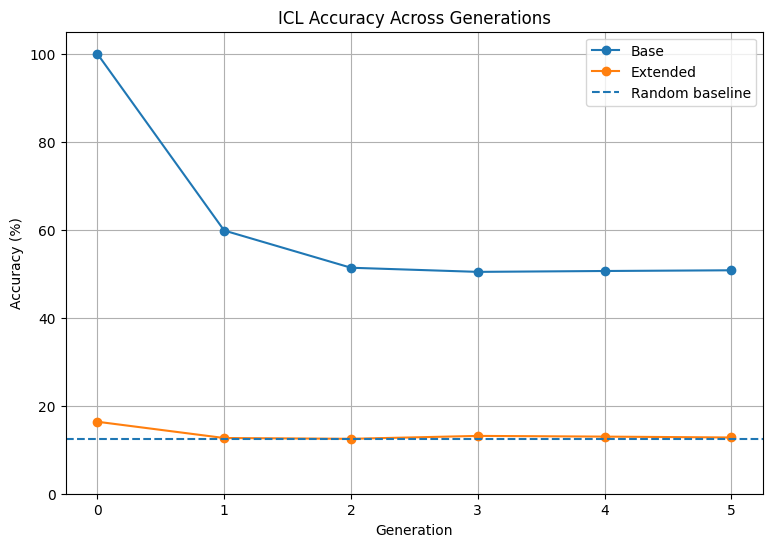

In [ ]:
plt.figure(figsize=(9, 6))

plt.plot(
    generations,
    [x * 100 for x in generation_metrics["base"]["accuracy"]],
    marker="o",
    label="Base"
)

plt.plot(
    generations,
    [x * 100 for x in generation_metrics["extended"]["accuracy"]],
    marker="o",
    label="Extended"
)

plt.axhline(
    12.5,
    linestyle="--",
    label="Random baseline"
)

plt.xlabel("Generation")
plt.ylabel("Accuracy (%)")
plt.title("ICL Accuracy Across Generations")
plt.xticks(generations)
plt.ylim(0, 105)
plt.legend()
plt.grid(True)
plt.show()

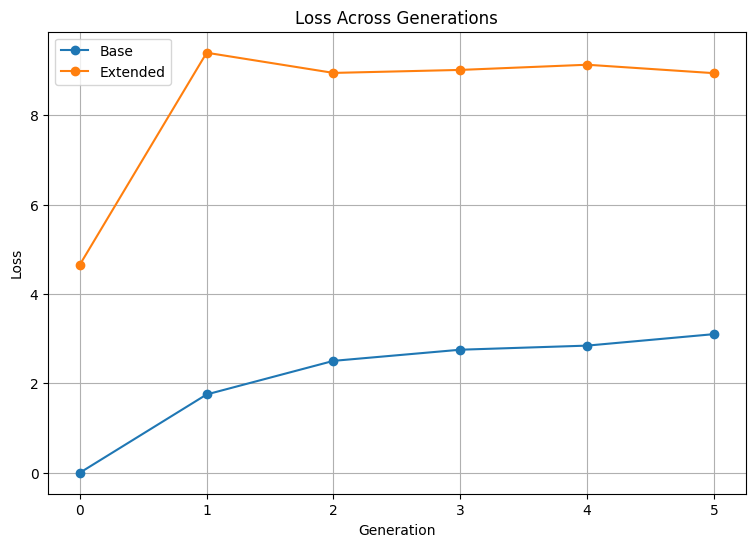

In [ ]:
plt.figure(figsize=(9, 6))

plt.plot(
    generations,
    generation_metrics["base"]["loss"],
    marker="o",
    label="Base"
)

plt.plot(
    generations,
    generation_metrics["extended"]["loss"],
    marker="o",
    label="Extended"
)

plt.xlabel("Generation")
plt.ylabel("Loss")
plt.title("Loss Across Generations")
plt.xticks(generations)
plt.legend()
plt.grid(True)
plt.show()

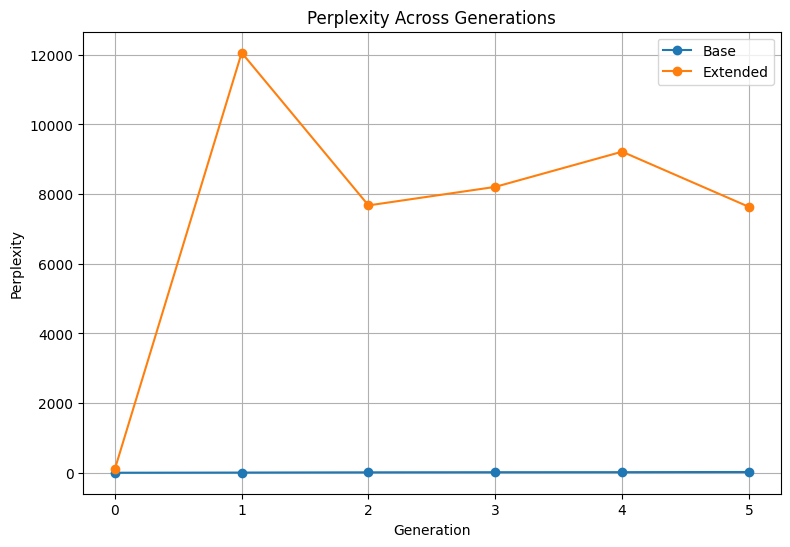

In [ ]:
plt.figure(figsize=(9, 6))

plt.plot(
    generations,
    generation_metrics["base"]["perplexity"],
    marker="o",
    label="Base"
)

plt.plot(
    generations,
    generation_metrics["extended"]["perplexity"],
    marker="o",
    label="Extended"
)

plt.xlabel("Generation")
plt.ylabel("Perplexity")
plt.title("Perplexity Across Generations")
plt.xticks(generations)
plt.legend()
plt.grid(True)
plt.show()

# Mechanistic Interpretability Model

In [ ]:
class InterpretableInductionTransformer(nn.Module):

    def __init__(
        self,
        vocab_size,
        max_seq_len,
        d_model=64,
        n_heads=4,
        n_layers=2,
        d_ff=128
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            d_model
        )

        self.position_embedding = nn.Embedding(
            max_seq_len,
            d_model
        )

        self.layers = nn.ModuleList([
            nn.TransformerEncoderLayer(
                d_model=d_model,
                nhead=n_heads,
                dim_feedforward=d_ff,
                dropout=0.1,
                batch_first=True
            )
            for _ in range(n_layers)
        ])

        self.output = nn.Linear(
            d_model,
            vocab_size
        )

    def forward(self, tokens, return_attention=False):

        batch_size, seq_len = tokens.shape

        positions = torch.arange(
            seq_len,
            device=tokens.device
        )

        positions = positions.unsqueeze(0).expand(
            batch_size,
            seq_len
        )

        x = (
            self.embedding(tokens)
            +
            self.position_embedding(positions)
        )

        attentions = []

        for layer in self.layers:

            # Multi-head attention
            attn_output, attn_weights = layer.self_attn(
                x,
                x,
                x,
                need_weights=True,
                average_attn_weights=False
            )

            # Save attention
            attentions.append(
                attn_weights.detach()
            )

            # Reproduce TransformerEncoderLayer
            x = layer.norm1(
                x + layer.dropout1(attn_output)
            )

            ff_output = layer.linear2(
                layer.dropout(
                    layer.activation(
                        layer.linear1(x)
                    )
                )
            )

            x = layer.norm2(
                x + layer.dropout2(ff_output)
            )

        logits = self.output(x)

        if return_attention:
            return logits, attentions

        return logits

In [ ]:
def convert_model(old_model):

    new_model = InterpretableInductionTransformer(
        vocab_size=VOCAB_SIZE,
        max_seq_len=2 * SEQ_PAIRS,
        d_model=D_MODEL,
        n_heads=N_HEADS,
        n_layers=N_LAYERS,
        d_ff=D_FF
    ).to(device)

    # Copy embeddings
    new_model.embedding.load_state_dict(
        old_model.embedding.state_dict()
    )

    new_model.position_embedding.load_state_dict(
        old_model.position_embedding.state_dict()
    )

    # Copy Transformer layers
    for old_layer, new_layer in zip(
        old_model.transformer.layers,
        new_model.layers
    ):

        new_layer.load_state_dict(
            old_layer.state_dict()
        )

    # Copy output layer
    new_model.output.load_state_dict(
        old_model.output.state_dict()
    )

    return new_model

In [ ]:
interpretable_g0 = convert_model(
    generation_models[0]
)

interpretable_g0.eval()

test_inputs, test_targets, test_symbols, test_values = (
    generate_icl_batch(1)
)

_, attentions = interpretable_g0(
    test_inputs,
    return_attention=True
)

# Induction-Head Scoring

In [ ]:
def induction_score(
    attentions,
    symbols
):

    scores = []

    # Final query symbol
    query_symbol = symbols[0, -1].item()

    # Find previous occurrences
    previous_positions = []

    for pos in range(len(symbols[0]) - 1):

        if symbols[0, pos].item() == query_symbol:
            previous_positions.append(pos)

    if len(previous_positions) == 0:
        return None

    # The value is immediately after the symbol
    target_positions = [
        pos * 2 + 1
        for pos in previous_positions
    ]

    # Final value prediction position
    query_position = symbols.shape[1] * 2 - 1

    for layer_idx, layer_attention in enumerate(attentions):

        # layer_attention:
        # [batch, heads, query, key]

        head_scores = []

        for head_idx in range(
            layer_attention.shape[1]
        ):

            attention = layer_attention[
                0,
                head_idx,
                query_position,
                :
            ]

            score = attention[
                target_positions
            ].sum().item()

            head_scores.append(score)

        scores.append(head_scores)

    return scores

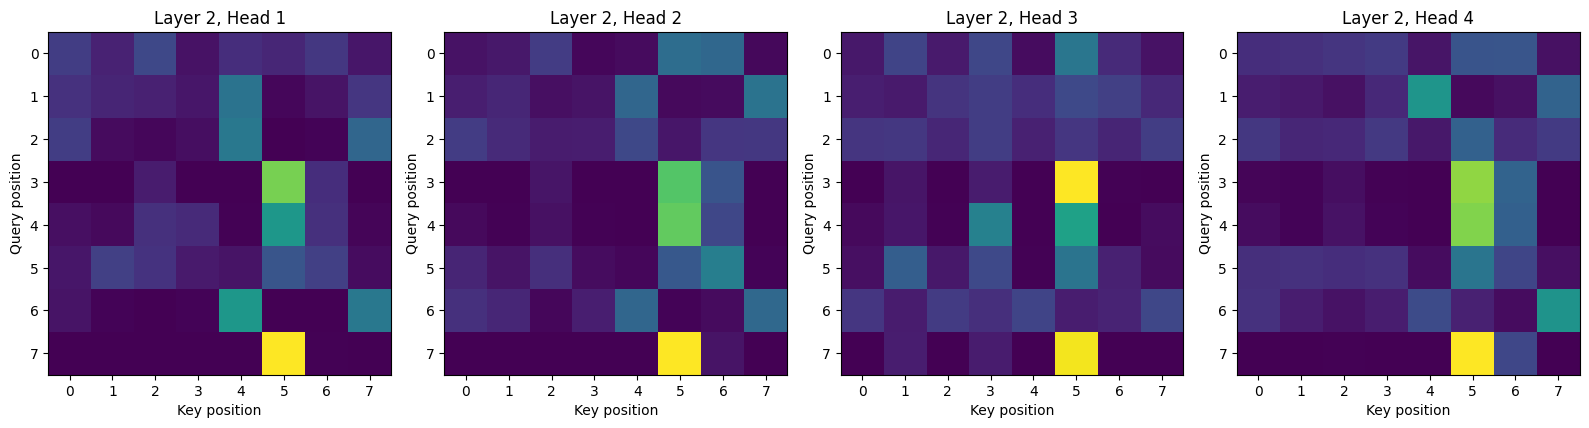

In [ ]:
import matplotlib.pyplot as plt

layer = 1

fig, axes = plt.subplots(
    1,
    N_HEADS,
    figsize=(16, 4)
)

for head in range(N_HEADS):

    attention = attentions[layer][
        0,
        head
    ].cpu().numpy()

    axes[head].imshow(attention)

    axes[head].set_title(
        f"Layer {layer + 1}, Head {head + 1}"
    )

    axes[head].set_xlabel("Key position")
    axes[head].set_ylabel("Query position")

plt.tight_layout()
plt.show()

In [ ]:
def get_induction_scores(model, num_examples=100):

    interpretable_model = convert_model(model)
    interpretable_model.eval()

    all_scores = []

    for _ in range(num_examples):

        inputs, _, symbols, _ = generate_icl_batch(1)

        inputs = inputs.to(device)

        logits, attention = interpretable_model(
            inputs,
            return_attention=True
        )

        scores = induction_score(
            attention,
            symbols
        )

        if scores is not None:
            all_scores.append(scores)

    return torch.tensor(all_scores)

# Induction-Head Analysis Across Generations

In [ ]:
base_induction_scores = []

for generation, model in enumerate(generation_models):

    scores = get_induction_scores(
        model,
        num_examples=100
    )

    mean_scores = scores.mean(dim=0)

    base_induction_scores.append(
        mean_scores.numpy()
    )

    print(
        f"Base G{generation}:"
    )

    print(mean_scores)

Base G0:
tensor([[0.3368, 0.0651, 0.1795, 0.3796],
        [0.8458, 0.6623, 0.9443, 0.7381]])
Base G1:
tensor([[0.2208, 0.3140, 0.3575, 0.2331],
        [0.4416, 0.3615, 0.4066, 0.3907]])
Base G2:
tensor([[0.2702, 0.1782, 0.4367, 0.3439],
        [0.3369, 0.3118, 0.2278, 0.3385]])
Base G3:
tensor([[0.4157, 0.2160, 0.2114, 0.2386],
        [0.2969, 0.1708, 0.2217, 0.4220]])
Base G4:
tensor([[0.3015, 0.2068, 0.3989, 0.3823],
        [0.3034, 0.2996, 0.3215, 0.3556]])
Base G5:
tensor([[0.4004, 0.3976, 0.0289, 0.3569],
        [0.4042, 0.3481, 0.2801, 0.3678]])


In [ ]:
extended_induction_scores = []

for generation, model in enumerate(
    extended_generation_models
):

    scores = get_induction_scores(
        model,
        num_examples=100
    )

    mean_scores = scores.mean(dim=0)

    extended_induction_scores.append(
        mean_scores.numpy()
    )

    print(
        f"Extended G{generation}:"
    )

    print(mean_scores)

Extended G0:
tensor([[0.1939, 0.2152, 0.2232, 0.0613],
        [0.3637, 0.2819, 0.0374, 0.3083]])
Extended G1:
tensor([[0.0283, 0.0583, 0.1453, 0.0176],
        [0.1379, 0.1057, 0.2044, 0.1693]])
Extended G2:
tensor([[0.1402, 0.2919, 0.0019, 0.0150],
        [0.1346, 0.2059, 0.1666, 0.1185]])
Extended G3:
tensor([[0.4148, 0.3401, 0.0512, 0.0696],
        [0.2983, 0.1478, 0.1505, 0.1758]])
Extended G4:
tensor([[0.3043, 0.4372, 0.3025, 0.0828],
        [0.1944, 0.2177, 0.1335, 0.1500]])
Extended G5:
tensor([[0.3467, 0.1223, 0.4380, 0.1764],
        [0.2486, 0.1652, 0.2290, 0.1430]])


In [ ]:
base_strength = [
    score.max()
    for score in base_induction_scores
]

extended_strength = [
    score.max()
    for score in extended_induction_scores
]

print("Base:", base_strength)
print("Extended:", extended_strength)

Base: [np.float32(0.9442987), np.float32(0.4415881), np.float32(0.43671829), np.float32(0.42195606), np.float32(0.39890587), np.float32(0.40418977)]
Extended: [np.float32(0.3636612), np.float32(0.20441121), np.float32(0.29186994), np.float32(0.4148407), np.float32(0.43716186), np.float32(0.4380272)]


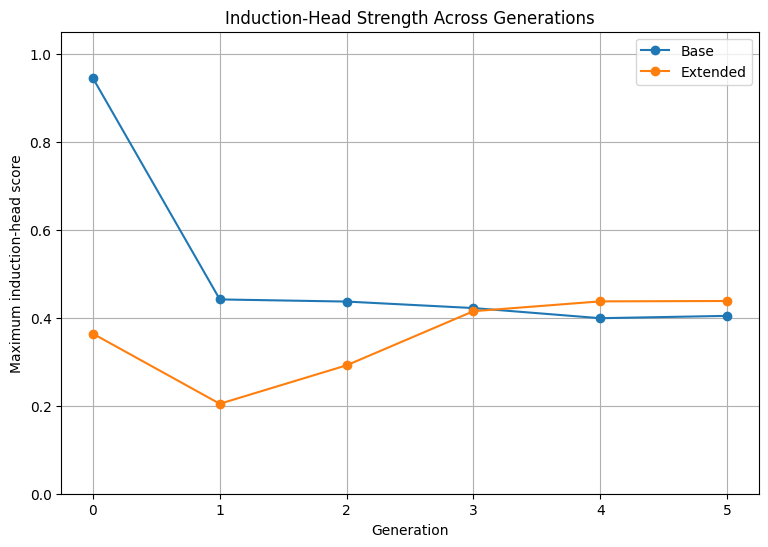

In [ ]:
plt.figure(figsize=(9, 6))

plt.plot(
    range(6),
    base_strength,
    marker="o",
    label="Base"
)

plt.plot(
    range(6),
    extended_strength,
    marker="o",
    label="Extended"
)

plt.xlabel("Generation")
plt.ylabel("Maximum induction-head score")
plt.title("Induction-Head Strength Across Generations")
plt.xticks(range(6))
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)

plt.show()

# Final Results Summary

In [ ]:
print("\n" + "=" * 60)
print("FINAL GENERATION METRICS")
print("=" * 60)

for experiment in ["base", "extended"]:

    print(f"\n{experiment.upper()}")

    for generation in generations:

        accuracy = generation_metrics[experiment]["accuracy"][generation]
        loss = generation_metrics[experiment]["loss"][generation]
        perplexity = generation_metrics[experiment]["perplexity"][generation]

        print(
            f"G{generation}: "
            f"Accuracy={accuracy * 100:.2f}% | "
            f"Loss={loss:.4f} | "
            f"Perplexity={perplexity:.4f}"
        )


FINAL GENERATION METRICS

BASE
G0: Accuracy=99.98% | Loss=0.0005 | Perplexity=1.0005
G1: Accuracy=59.82% | Loss=1.7520 | Perplexity=5.7662
G2: Accuracy=51.36% | Loss=2.5035 | Perplexity=12.2251
G3: Accuracy=50.42% | Loss=2.7527 | Perplexity=15.6843
G4: Accuracy=50.62% | Loss=2.8443 | Perplexity=17.1902
G5: Accuracy=50.78% | Loss=3.1012 | Perplexity=22.2238

EXTENDED
G0: Accuracy=16.36% | Loss=4.6556 | Perplexity=105.1735
G1: Accuracy=12.66% | Loss=9.3976 | Perplexity=12059.3242
G2: Accuracy=12.48% | Loss=8.9458 | Perplexity=7675.8083
G3: Accuracy=13.14% | Loss=9.0129 | Perplexity=8208.0059
G4: Accuracy=12.98% | Loss=9.1289 | Perplexity=9217.8623
G5: Accuracy=12.78% | Loss=8.9403 | Perplexity=7633.6040
